## Neural Network
[Artificial neural networks (ANNs)](https://en.wikipedia.org/wiki/Artificial_neural_network), usually simply called neural networks (NNs) or neural nets, are computing systems inspired by the biological neural networks that constitute animal brains.
<p>
An ANN is based on a collection of connected units or nodes called artificial neurons, which loosely model the neurons in a biological brain. Each connection, like the synapses in a biological brain, can transmit a signal to other neurons. An artificial neuron receives signals then processes them and can signal neurons connected to it. The "signal" at a connection is a real number, and the output of each neuron is computed by some non-linear function of the sum of its inputs. The connections are called edges. Neurons and edges typically have a weight that adjusts as learning proceeds. The weight increases or decreases the strength of the signal at a connection. Neurons may have a threshold such that a signal is sent only if the aggregate signal crosses that threshold.
<p>
Typically, neurons are aggregated into layers. Different layers may perform different transformations on their inputs. Signals travel from the first layer (the input layer), to the last layer (the output layer), possibly after traversing the layers multiple times.
<p>
Met een neuraal net kun je dus ook voorspellingen maken, net als met regressie of Naive Bayes Classification of Decision Trees.
<p>
Om deze methode te kunnen toepassen, lezen we eerst weer de benodigde libraries in:




In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split

from sklearn import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Voorbeeld 1: Pinguins
Via panda's wordt het bestand penguins_size.csv ingelezen.

De NaN's worden uit de dataframe gehaald:


In [ ]:
# =====================Inladen bestanden=======================================
# Tabellen met parameters ophalen uit dit bestand.
df = pd.read_csv("penguins_size.csv")
# =============================================================================
df = df.dropna()
df

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE
...,...,...,...,...,...,...,...
338,Gentoo,Biscoe,47.2,13.7,214.0,4925.0,FEMALE
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [ ]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
culmen_length_mm,334.0,43.994311,5.460521,32.1,39.5,44.5,48.575,59.6
culmen_depth_mm,334.0,17.160479,1.967909,13.1,15.6,17.3,18.700,21.5
flipper_length_mm,334.0,201.014970,14.022175,172.0,190.0,197.0,213.000,231.0
body_mass_g,334.0,4209.056886,804.836129,2700.0,3550.0,4050.0,4793.750,6300.0


## Neuraal netwerk voor regressie
Laten we eens kijken of we een voorspelling kunnen maken. In dit voorbeeld gaan we kijken of we het gewicht (bodymass) van een pinguin kunnen voorspellen op basis van flipperlengte, snavellengte en snaveldiepte.
<p>
Dat doen we door eerst de data te verdelen in een trainings-set (40%) en een test-set (60%). Met de trainings-set 'train' je het model = laat je het model berekenen welke 'body mass' bij welke snavellengte- en diepte & flipperlengte hoort.
<p>
Met de test-set voorspel je vervolgens welke 'body mass' bij welke snavellengte- en diepte & flipperlengte hoort.   

In [ ]:
X = df.drop(['species', 'island', 'sex', 'body_mass_g'], axis = 1)
y = df['body_mass_g']


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.6)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

Vervolgens trainen we het model:

In [ ]:
model = MLPRegressor(hidden_layer_sizes = (64, 64, 64),
                     activation = "relu",
                     random_state = 42, max_iter = 2000)

model.fit(X_train, y_train)
y_pred = model.predict(X_val)

/usr/local/lib/python3.9/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


Is dit neurale netwerk nu een goede voorspeller?

In [ ]:
mae = metrics.mean_absolute_error(y_val, y_pred)
mse = metrics.mean_squared_error(y_val, y_pred)
rmse = mse**0.5
r2 = metrics.r2_score(y_val, y_pred)


print(f"""
Mean Absolute Error: \t{mae:.2f}
Root Mean Square Error: \t{rmse:.2f}
r2: \t{r2:.2f}
""")


Mean Absolute Error: 	251.17
Root Mean Square Error: 	329.41
r2: 	0.84



In [ ]:
df3 = pd.DataFrame()

df3['body_mass_g'] = y_val
df3['Predicted Mass'] = y_pred


weight = df3[['body_mass_g', 'Predicted Mass']].pct_change(axis = 'columns', periods = 1 ).abs()
total = sum(weight['Predicted Mass'])

average_miscalc = (total / len(weight)) * 100
print(f"De afwijking tussen predicted weight en daadwerkelijk gewicht is gemiddeld {round(average_miscalc, 2)} % \n\n\n" )

De afwijking tussen predicted weight en daadwerkelijk gewicht is gemiddeld 6.02 % 





We kunnnen een neuraal netwerk dus gebruiken bij het voorspellen van een continue variabele.

## Scatterplot
In onderstaand scatterplot wordt het voorspelde gewicht en het werkelijke gewicht tegen elkaar uitgezet:

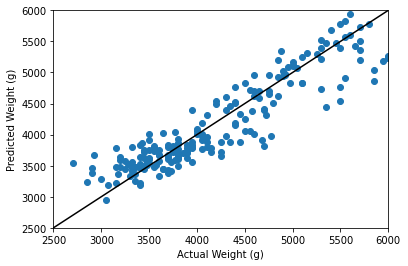

In [ ]:
plt.scatter(y_val, y_pred)
plt.xlim(2500, 6000)
plt.ylim(2500, 6000)
plt.ylabel('Predicted Weight (g)')
plt.xlabel('Actual Weight (g)')
plt.plot([0, 6000], [0,6000], 'black') #1 to 1 line
plt.show()

Het model van het neural network heeft predictions gemaakt en deze staan uitgezet tegen het daadwerkelijke gewicht van de pinguins. In het ideale geval liggen alle punten op de ideaallijn en hoe dichter deze bij de lijn liggen, hoe beter de voorspellingen zijn. Hieruit blijkt dat het neural network een redelijk goed model is voor het bepalen van een continue variabele.

# Voorbeeld 2: VU studenten dataset
We gaan kijken of we een neuraal regressiemodel kunnen maken, dat op basis van leeftijd en de 'depress'-score het inkomen voorspelt.

In [ ]:
df = pd.read_excel("vustudentanalytics.xlsx")
df = df.loc[:, ["age", "depress","income"]]
df.head() # We take a look at the first 5 rows


,age,depress,income
0,57,6.0,800.0
1,20,0.0,350.0
2,18,0.0,NaN
3,78,16.0,900.0
4,54,4.0,1500.0


In [ ]:
df.shape

(5000, 3)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   age      5000 non-null   int64  
 1   depress  4911 non-null   float64
 2   income   4317 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 117.3 KB


We zien dat er 5.000 regels in de dataset zitten, maar in de depress- en income-kolom ontbreken er waarden.<p>
Om een neural netwerk te kunnen maken, mogen er geen NULL of NaN waarden in de tabel zitten.<p>
Die gaan we dus eerst verwijderen.

In [ ]:
df_analyse = df.dropna()
df_analyse.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 4242 entries, 0 to 4998
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   age      4242 non-null   int64  
 1   depress  4242 non-null   float64
 2   income   4242 non-null   float64
dtypes: float64(2), int64(1)
memory usage: 132.6 KB


We houden 4.242 regels over. Met deze selectie gaan we nu verder.<p>


Nog even een plaatje:

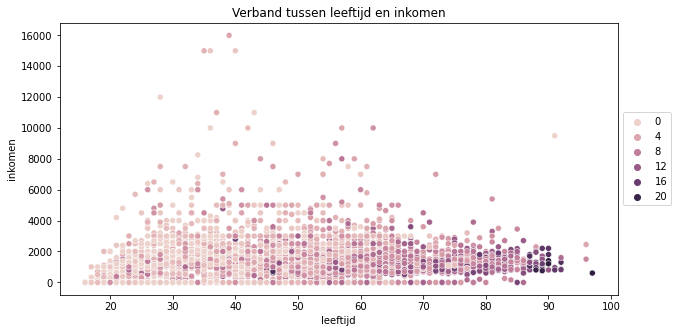

In [ ]:
sns.set_palette("bright")
plt.figure(figsize=(10,5))
ax = sns.scatterplot(x='age',
                     y='income',
                     data=df_analyse,
                     hue='depress')
plt.title('Verband tussen leeftijd en inkomen', color='black')
plt.xlabel('leeftijd')
plt.ylabel('inkomen')
plt.legend(title='Depress-score')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

## Neuraal netwerk voor regressie
We trainen en testen het model:

In [ ]:
X = df_analyse.drop(['income'], axis = 1)
y = df_analyse['income']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.6)

In [ ]:
# deze code alleen gebruiken als je voor de X maar 1 oorzakelijke variabele gebruikt (bijv alleen leeftijd of alleen ' depress')

#X_train = pd.Series(X_train).array
#X_train = X_train.reshape(-1,1)

#X_val = pd.Series(X_val).array
#X_val = X_val.reshape(-1,1)

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

We gebruiken als neuraal netwerkmodel de [MLP Regressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html):<br>

tutorial in de vorm van een [video](https://www.youtube.com/watch?v=_JG71FIP1rk).

In [ ]:
model = MLPRegressor(hidden_layer_sizes = (64, 64, 64),
                     activation = "relu",
                     random_state = 42, max_iter = 2000)

model.fit(X_train, y_train)
y_pred = model.predict(X_val)

Is dit neuraal net nu een goede voorspeller?

In [ ]:
mae = metrics.mean_absolute_error(y_val, y_pred)
mse = metrics.mean_squared_error(y_val, y_pred)
rmse = mse**0.5
r2 = metrics.r2_score(y_val, y_pred)


print(f"""
Mean Absolute Error: \t{mae:.2f}
Root Mean Square Error: \t{rmse:.2f}
r2: \t{r2:.2f}
""")


Mean Absolute Error: 	810.63
Root Mean Square Error: 	1307.87
r2: 	0.06



Vergeleken met het gemiddelde inkomen zijn de [MAR](https://en.wikipedia.org/wiki/Mean_absolute_error) en de [RMSE](https://en.wikipedia.org/wiki/Root-mean-square_deviation) hoog.<br>
Een r-kwadraat van 0,06 voorspelt ook niet veel goeds, namelijk: geen verband.

In [ ]:
df2 = pd.DataFrame()

df2['Income'] = y_val
df2['Predicted income'] = y_pred
df2

,Income,Predicted income
1832,1600.0,990.540059
2259,2500.0,1563.094016
4108,816.0,1252.619593
666,2000.0,1547.109408
1236,200.0,1046.573297
...,...,...
4012,1800.0,1389.687245
1316,-8.0,1217.812060
1374,700.0,1397.920372
173,690.0,1003.600621


Een werkelijk inkomen van -8, en een bijbehorende voorspelling van 1.217,8??

In [ ]:
weight = df2[['Income', 'Predicted income']].pct_change(axis = 'columns', periods = 1 ).abs()
total = sum(weight['Predicted income'])

average_miscalc = (total / len(weight)) * 100
print(f"De afwijking tussen predicted income en daadwerkelijk income is gemiddeld {round(average_miscalc, 2)} % \n\n\n" )

De afwijking tussen predicted income en daadwerkelijk income is gemiddeld 2272.83 % 





Conclusie: leeftijd en 'depress'-score zijn een hele slechte voorspeller voor het inkomen:<br>
de afwijking tussen werkelijk en voorspeld is meer dan 2.000 %, dat is wat veel van het goede ..

## Scatterplot
De scatterplot bevestigt deze conclusie:

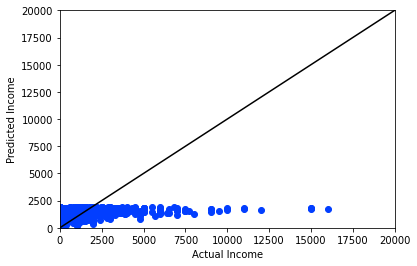

In [ ]:
plt.scatter(y_val, y_pred)
plt.xlim(-8, 20000)
plt.ylim(-8, 20000)
plt.ylabel('Predicted Income')
plt.xlabel('Actual Income')
plt.plot([-8, 20000], [-8,20000], 'black') #1 to 1 line
plt.show()

Bijna geen enkel blauw punt ligt op de 'ideale' lijn, dit is geen goed voorspelmodel.

#Nadeel van een neuraal netwerk
Probeer de uitkomst van bovenstaande regressie-analyse met behulp van een neuraal netwerk maar eens uit te leggen aan een leek:<br>
- Hoe ziet het voorspelmodel er nu uit?<br>
- Wat gebeurt er precies in / tussen de 3 hidden layers met 64 neuronen?<br>

<p>

Bij de andere voorspelmodellen (lineaire regressie, naive Bayes en beslisbomen) is nog enigszins te volgen wat het model doet. Het neurale netwerk is een fijn voorbeeld van een black box:<br>
alleen wat er in gaat (data) en wat er uitkomt (voorspelling) is bekend.<br>
<p>
https://en.wikipedia.org/wiki/Black_box

